# Get Data

In [122]:
import numpy as np
import pandas as pd 

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

In [124]:
import re

In [125]:
df = pd.read_csv('./data/train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [126]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [127]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [128]:
df.isna().mean() * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [129]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [130]:
def value_counts(df):
    for col in df.columns:
        print(f'\nUnique Values Counts for {col}:\n')
        print(df[col].value_counts())

In [131]:
value_counts(df)


Unique Values Counts for PassengerId:

PassengerId
1      1
599    1
588    1
589    1
590    1
      ..
301    1
302    1
303    1
304    1
891    1
Name: count, Length: 891, dtype: int64

Unique Values Counts for Survived:

Survived
0    549
1    342
Name: count, dtype: int64

Unique Values Counts for Pclass:

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Unique Values Counts for Name:

Name
Braund, Mr. Owen Harris                     1
Boulos, Mr. Hanna                           1
Frolicher-Stehli, Mr. Maxmillian            1
Gilinski, Mr. Eliezer                       1
Murdlin, Mr. Joseph                         1
                                           ..
Kelly, Miss. Anna Katherine "Annie Kate"    1
McCoy, Mr. Bernard                          1
Johnson, Mr. William Cahoone Jr             1
Keane, Miss. Nora A                         1
Dooley, Mr. Patrick                         1
Name: count, Length: 891, dtype: int64

Unique Values Counts for Sex:

Sex
male  

## Columns According To Data Type And Target

In [132]:
df_cat_columns = ['Pclass', 'Embarked', 'Cabin', 'Ticket', 'Sex', 'Name']
df_num_columns = ['PassengerId', 'Age', 'SibSp', 'Parch', 'Fare']
df_target_column = 'Survived'

## Check target distribution

In [133]:
print(df[df_target_column].value_counts())
value_counts_pct = (df[df_target_column].value_counts() / df[df_target_column].value_counts().sum()).mul(100).round(2).astype(str) + '%'
print(value_counts_pct)

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.62%
1    38.38%
Name: count, dtype: object


## Split Data

The target distribution is reasonably balanced so no specific handling is needed. 

In [134]:
X = df.drop('Survived', axis=1)
y = df[df_target_column]
print(X.columns)

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [135]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Data Exploration 

## Questions

1. Fare and PClass (Ticket Class) are very strongly inversly correlated. Since the lower (better) the PClass the higher the Fare. Maybe, We could separate the fares according to pclass or according to a set of categories(Cheap, Moderate, Expensive)?
2. PClass and Survived are inversely correlated. The richer you are the more your chances of survival?
3. Age and PClass are inversely correlated. The older you are the richer you are? But age does not have a correlation to Survived So are there other influences?
4. So no missing tickets but 558 unique tickets over 712. Let's see what the tickets that are repeating look like is it an error or do they have something in common? if so, what? and could it be useful?
5. Also we have 159 cabins and 117 unique cabins so the difference are people who shared cabins. Does cabin sharing influence your chances of survival?
6. Can we separate Cabin according to their Character and see what it gives? Also compare it to PClass and Fare.
7. Strong Correlation between Parch (Number of Parents and children) and SibSp (Number of sibling and spouses). Does combining the two as Family members have an influence on the prediction?
8. Each name has a title 'miss', 'mr' maybe others, do they correspond only to the sex or are there other titles. Example: seaman, captain... And if soo then can those titles be used in relation to survival or wealth?


In [136]:
X_train.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,712.000000,712.000000,572.000000,712.000000,712.000000,712.000000
mean,448.234551,2.330056,29.498846,0.553371,0.379213,32.586276
std,256.731423,0.824584,14.500059,1.176404,0.791669,51.969529
min,1.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,224.750000,2.000000,21.000000,0.000000,0.000000,7.925000
50%,453.500000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,673.500000,3.000000,38.000000,1.000000,0.000000,30.500000
max,891.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [137]:
y_train.describe()

count    712.000000
mean       0.376404
std        0.484824
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: Survived, dtype: float64

In [138]:
df_train = pd.concat([X_train, y_train], axis=1)

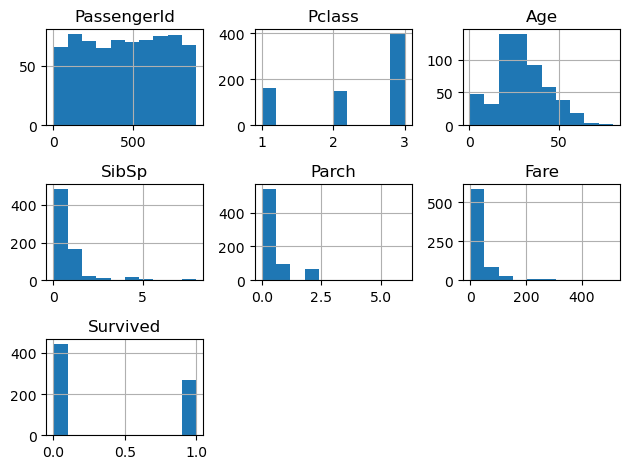

In [139]:
df_train.hist()
plt.tight_layout()
plt.show()

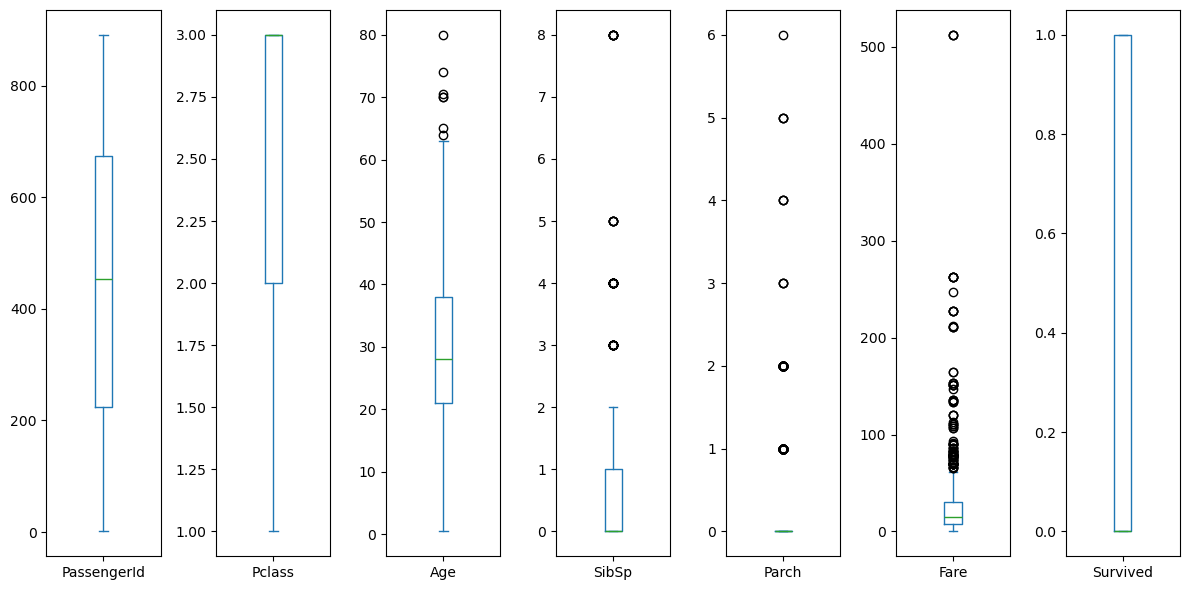

In [140]:
df_train.plot(kind='box', subplots=True, figsize=(12, 6))
plt.tight_layout()
plt.show()

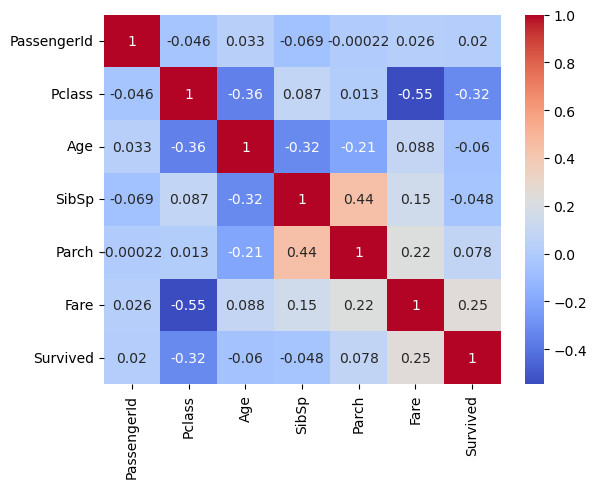

In [141]:
correlations = df_train.select_dtypes(include='number').corr()
sns.heatmap(data=correlations, cmap='coolwarm', annot=True)
plt.show()

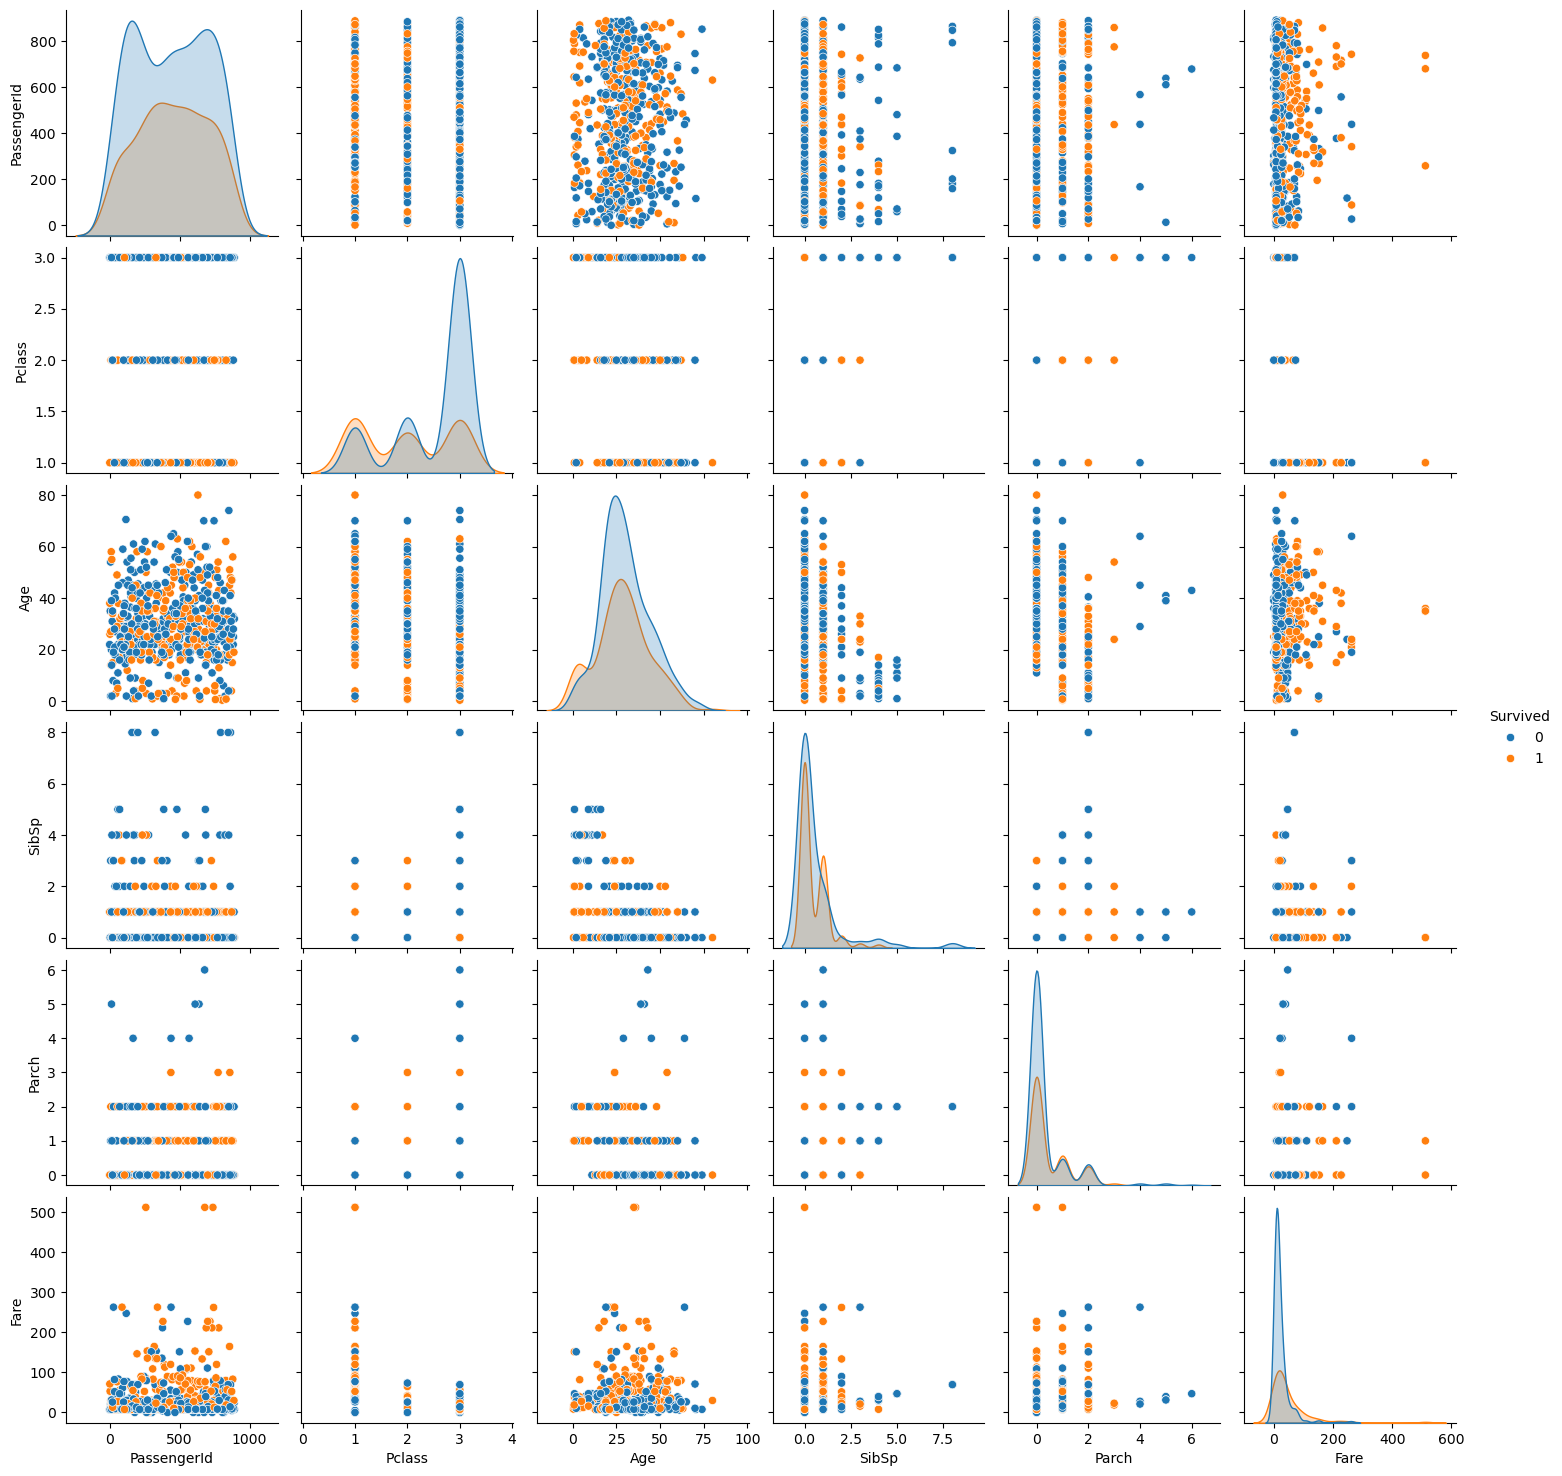

In [142]:
sns.pairplot(data=df_train.select_dtypes(include='number'), hue='Survived')
plt.show()

So the if you are between 0 and 25 your chances of survival increase.
The more expensive the ticket fare the more you survive.
The better your PClass the more survival chances.

In [143]:
df_train[df_cat_columns].describe(exclude='number')

,Embarked,Cabin,Ticket,Sex,Name
count,710,159,712,712,712
unique,3,117,558,2,712
top,S,C23 C25 C27,CA. 2343,male,"Partner, Mr. Austen"
freq,525,4,7,467,1


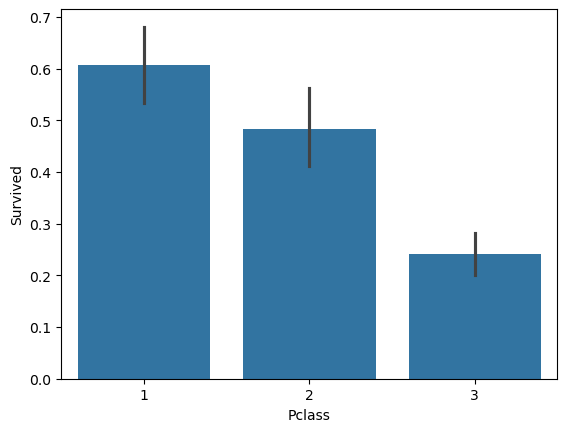

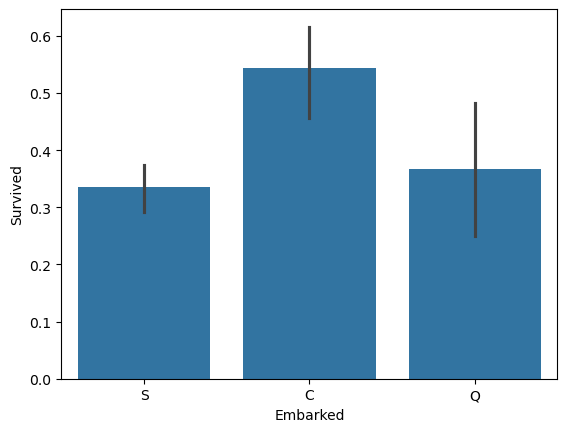

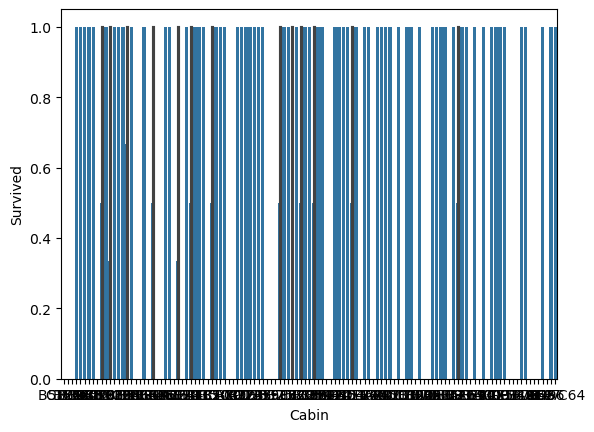

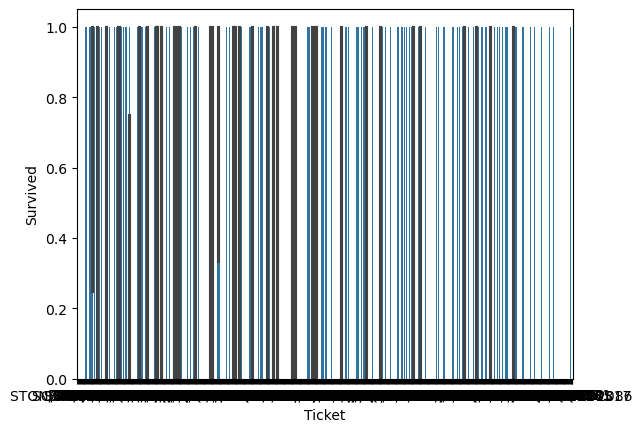

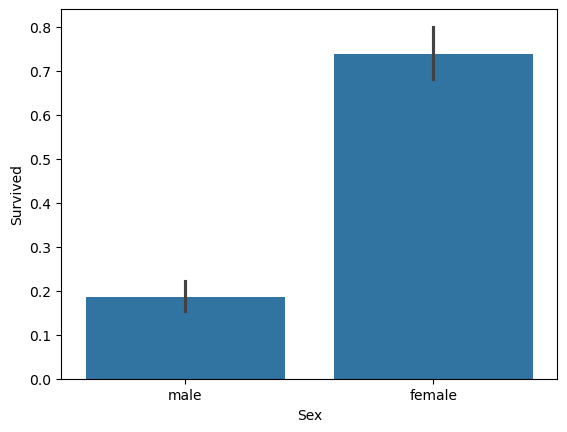

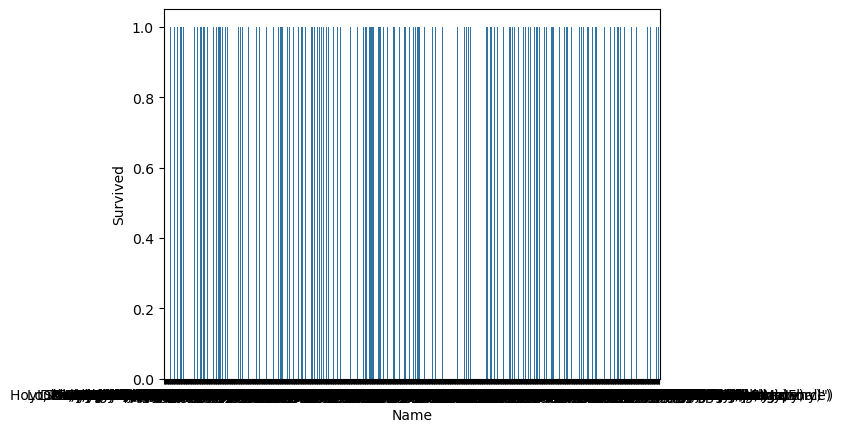

In [144]:
for col in df_cat_columns:
    sns.barplot(x=col, y='Survived', data=df_train)
    plt.show()

## Answer 1:
Fare and PClass (Ticket Class) are very strongly inversly correlated. Since the lower (better) the PClass the higher the Fare. Maybe, We could separate the fares according to pclass or according to a set of categories(Cheap, Moderate, Expensive)?

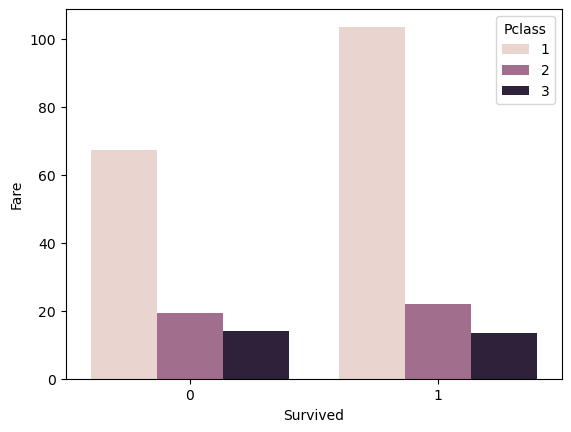

In [145]:
sns.barplot(
    data=df_train,
    x='Survived',
    y='Fare',
    hue='Pclass',
    estimator='mean',
    errorbar=None
)

plt.show()


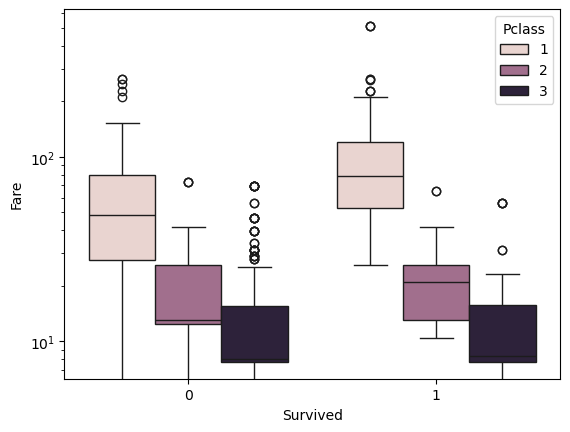

In [146]:
sns.boxplot(
    data=df_train,
    x='Survived',
    y='Fare',
    hue='Pclass'
)
plt.yscale('log')  
plt.show()

Obviously, All survivors from all pclass {1, 2, 3} paid more in average.

## Answer 2:
PClass and Survived are inversely correlated. The richer you are the more your chances of survival?

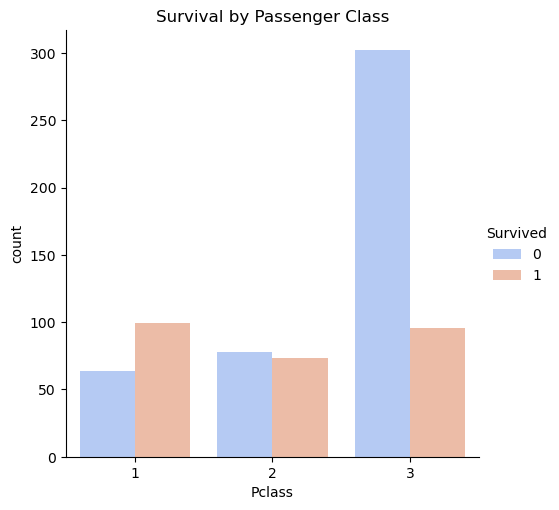

In [147]:
sns.catplot(data=df_train, x='Pclass', hue='Survived', kind='count', palette='coolwarm')
plt.title('Survival by Passenger Class')
plt.show()


Most of pclass 3 died, and a greater number of pclass 2 and 3 died than survived but more than 50% of pclass 1 survived. 

## Answer 3:
Age and PClass are inversely correlated. The older you are the richer you are? But age does not have a correlation to Survived So are there other influences?

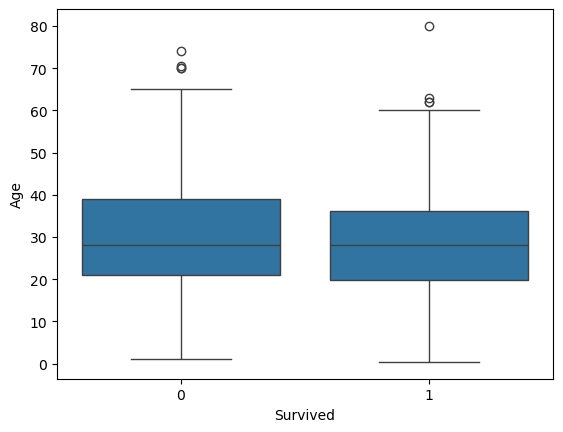

In [148]:
sns.boxplot(data=df_train, x='Survived', y='Age',)
plt.show()

No correlation between age and survived, as expected.

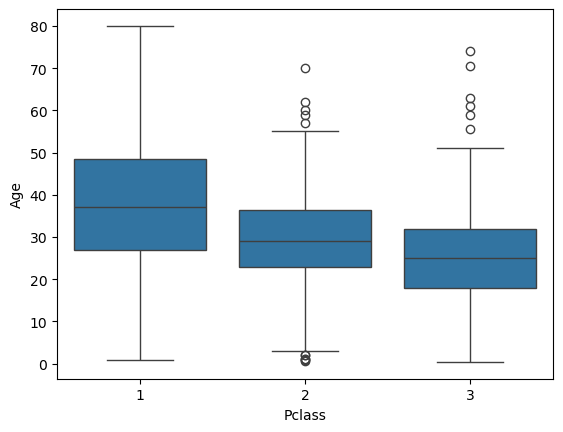

In [149]:
sns.boxplot(data=df_train, x='Pclass', y='Age',)
plt.show()

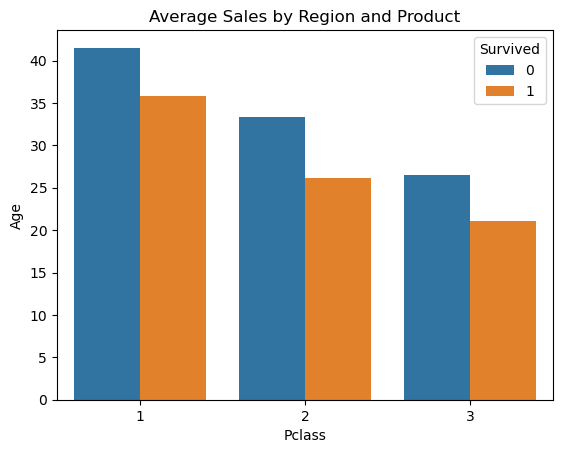

In [150]:
sns.barplot(
    data=df_train,
    x='Pclass',
    y='Age',
    hue='Survived',
    estimator='mean',
    errorbar=None
)

plt.title('Average Sales by Region and Product')
plt.show()


It is because The wealthy are older that survivors are older on average.

## Answer 4:
So no missing tickets but 558 unique tickets over 712. Let's see what the tickets that are repeating look like is it an error or do they have something in common? if so, what? and could it be useful?

In [151]:
df_duplicates = df_train[df_train.groupby('Ticket')['Ticket'].transform('count') > 1].copy()
print(df_duplicates['Ticket'].value_counts().head(5))


Ticket
CA. 2343    7
347082      6
1601        6
CA 2144     6
3101295     5
Name: count, dtype: int64


Testing with top 5 as there are too many unique values.

In [152]:
top_5_tickets = (
    df_duplicates['Ticket']
    .value_counts()
    .head(10)
    .index
)

df_top_tickets = df_duplicates[df_duplicates['Ticket'].isin(top_5_tickets)]

ct = pd.crosstab(
    df_top_tickets['Ticket'],
    df_top_tickets['Cabin']
)

print(ct)


Cabin   C22 C26  C23 C25 C27
Ticket                      
113781        3            0
19950         0            4


In [153]:
print(df_top_tickets['Cabin'])

813            NaN
542            NaN
7              NaN
305        C22 C26
302            NaN
708            NaN
597            NaN
164            NaN
24             NaN
692            NaN
678            NaN
787            NaN
74             NaN
567            NaN
324            NaN
271            NaN
88     C23 C25 C27
278            NaN
59             NaN
169            NaN
179            NaN
341    C23 C25 C27
50             NaN
792            NaN
180            NaN
638            NaN
171            NaN
16             NaN
480            NaN
374            NaN
119            NaN
610            NaN
297        C22 C26
826            NaN
438    C23 C25 C27
386            NaN
863            NaN
509            NaN
846            NaN
824            NaN
850            NaN
159            NaN
838            NaN
683            NaN
27     C23 C25 C27
498        C22 C26
201            NaN
13             NaN
686            NaN
71             NaN
Name: Cabin, dtype: object


Too Many missing cabins to make a conclusion

## Answer 5:
Also we have 159 cabins and 117 unique cabins so the difference are people who shared cabins. Does cabin sharing influence your chances of survival?

In [154]:
print(df_train['Cabin'].nunique())

117


In [155]:
df_duplicates = df_train.copy()

In [156]:
df_duplicates['SharedCabin'] = df_duplicates['Cabin'].duplicated(keep=False) == False
print(df_duplicates['SharedCabin'].astype('int').value_counts())

df_duplicates['SharedCabin'] = df_duplicates['SharedCabin'].astype('int')

SharedCabin
0    630
1     82
Name: count, dtype: int64


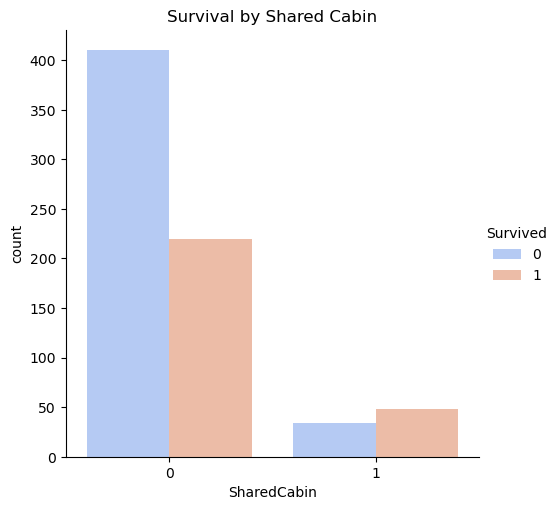

In [157]:
sns.catplot(data=df_duplicates, x='SharedCabin', hue='Survived', kind='count', palette='coolwarm')
plt.title('Survival by Shared Cabin')
plt.show()

In [158]:
shared_cabin_corr = df_duplicates[['SharedCabin', 'Survived']].corr()
print(shared_cabin_corr)

             SharedCabin  Survived
SharedCabin     1.000000  0.155605
Survived        0.155605  1.000000


Yes, if you shared a cabin you had higher chances of surviving. with a 0.155 correlation with Survived

## Answer 6:
6. Can we separate Cabin according to their Character and see what it gives? Also compare it to PClass and Fare.


In [159]:
df_duplicates = df_train.copy()

In [160]:
def mask_regex_cabin(cabin):
    if pd.isna(cabin):
        return
    
    letters = re.findall(r'([A-Za-z])\d+', cabin)
    
    if not letters:
        return None
    
    if all(letter == letters[0] for letter in letters):
        return letters[0]
    
    return ' '.join(letters)


df_duplicates['CabinSymbol'] = df_duplicates['Cabin'].apply(mask_regex_cabin)

print(df_duplicates['CabinSymbol'].value_counts())

CabinSymbol
C    52
B    38
E    25
D    18
A    10
F     8
G     6
Name: count, dtype: int64


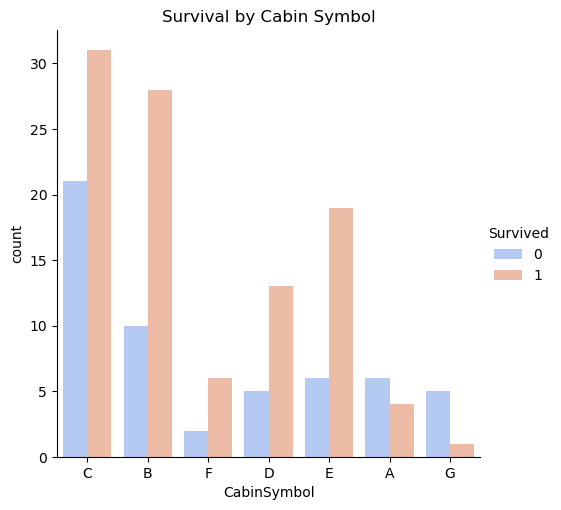

In [161]:
sns.catplot(data=df_duplicates, x='CabinSymbol', hue='Survived', kind='count', palette='coolwarm')
plt.title('Survival by Cabin Symbol')
plt.show()

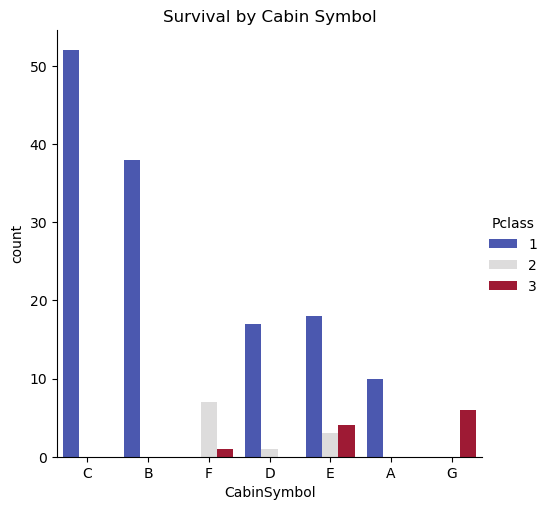

In [162]:
sns.catplot(data=df_duplicates, x='CabinSymbol', hue='Pclass', kind='count', palette='coolwarm')
plt.title('Survival by Cabin Symbol')
plt.show()

Cabin Letters seem to be directly related to Pclass probably Some cabin are more expensive than the other. A surface observation of levels of cabins would be: 

Pclass 1 exclusive: A, B, C 

Pclass 1 and 2: D 

Pclass 1, 2, 3: E 

Pclass 2 and 3: F

Pclass 3 exclusive: G

So probably A to G from best to worst.
let's confirm with fare.

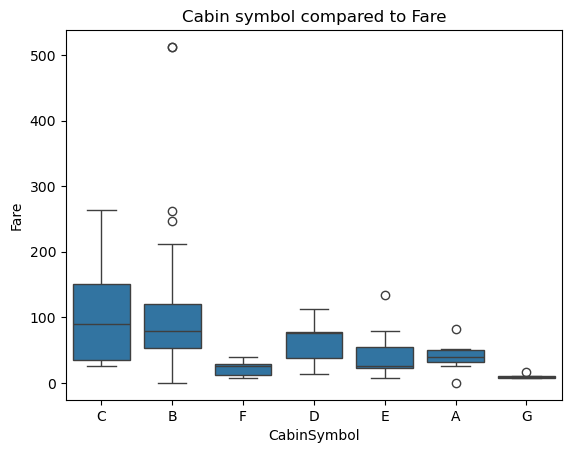

In [163]:
sns.boxplot(data=df_duplicates, x='CabinSymbol', y='Fare')
plt.title("Cabin symbol compared to Fare")
plt.show()

Let's get the mean of prices and sort them according to cabin symbol

In [164]:
grouped = df_duplicates.groupby(['CabinSymbol'])
print(grouped)

In [165]:
def mean_no_outliers(x):
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    filtered = x[(x >= q1 - 1.5*iqr) & (x <= q3 + 1.5*iqr)]
    return filtered.mean()

In [166]:
mean_values = grouped['Fare'].agg(mean_no_outliers).sort_values(ascending=False).reset_index()
print(mean_values)

  CabinSymbol        Fare
0           C  103.056648
1           B   77.898285
2           D   61.034961
3           A   40.465100
4           E   37.700000
5           F   23.406250
6           G    8.775000


There are probably other factors in play affecting the price but it doesn't matter as the relationship between the cabin letter and survival exists even if is it not entirely related to price it could also be related to other things like location. This could be a good feature to engineer

## Answer 7:
7. Strong Correlation between Parch (Number of Parents and children) and SibSp (Number of sibling and spouses). Does combining the two as Family members have an influence on the prediction?

In [167]:
df_duplicates = df_train.copy()
df_duplicates['Ncompanions'] = df_duplicates['Parch'].add(df_duplicates['SibSp'])

print(df_duplicates[['Ncompanions', 'Parch', 'SibSp']])

     Ncompanions  Parch  SibSp
331            0      0      0
733            0      0      0
382            0      0      0
704            1      0      1
813            6      2      4
..           ...    ...    ...
106            0      0      0
270            0      0      0
860            2      0      2
435            3      2      1
102            1      1      0

[712 rows x 3 columns]


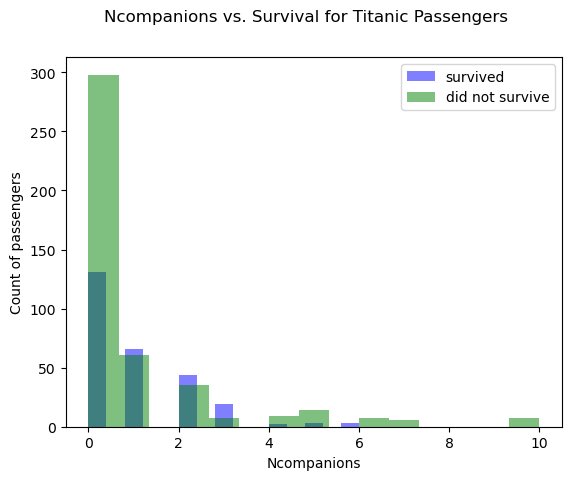

In [168]:
fig, ax = plt.subplots()

ax.hist(df_duplicates[df_duplicates["Survived"]==1]["Ncompanions"], bins=15, alpha=0.5, color="blue", label="survived")
ax.hist(df_duplicates[df_duplicates["Survived"]==0]["Ncompanions"], bins=15, alpha=0.5, color="green", label="did not survive")

ax.set_xlabel("Ncompanions")
ax.set_ylabel("Count of passengers")

fig.suptitle("Ncompanions vs. Survival for Titanic Passengers")

ax.legend();

The more people you have with you the greater your chances of dying?

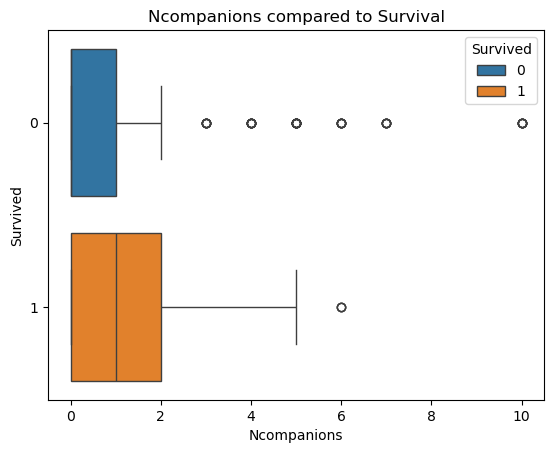

In [169]:
sns.boxplot(data=df_duplicates, x='Ncompanions', y='Survived', hue='Survived', orient="h")
plt.title("Ncompanions compared to Survival")
plt.legend(title='Survived')
plt.show()

According to this the More people you have the more your chances of survival. But, Not by much it is fairly even. The other values are outlies in the previous graph

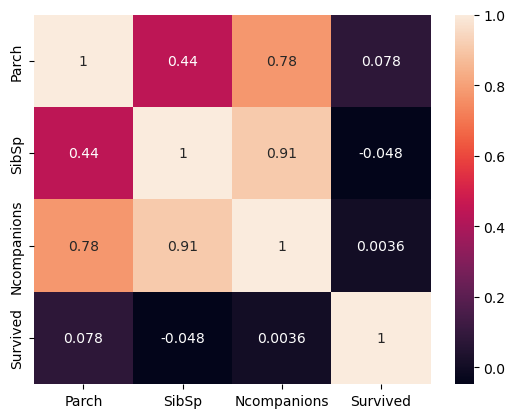

In [170]:
corr_ncompanions = df_duplicates[['Parch', 'SibSp', 'Ncompanions', 'Survived']].corr()   # Pearson correlation
sns.heatmap(corr_ncompanions, annot=True)
plt.show()

Not much to comment on adding the two columns doesn't change much

## Answer 8:
8. Each name has a title 'miss', 'mr' maybe others, do they correspond only to the sex or are there other titles. Example: seaman, captain... And if soo then can those titles be used in relation to survival or wealth? 

In [171]:
df_duplicates = df_train.copy()

In [172]:
def mask_regex(name):
    match = re.match(r".*?,(.*?)\..*", name)
    return match.group(1) if match else None

df_duplicates['title'] = df_duplicates['Name'].apply(mask_regex)

print(df_duplicates['title'].value_counts())

title
Mr              419
Miss            143
Mrs              96
Master           33
Rev               5
Dr                5
Major             2
Col               2
Mlle              2
Capt              1
Mme               1
Ms                1
the Countess      1
Lady              1
Name: count, dtype: int64


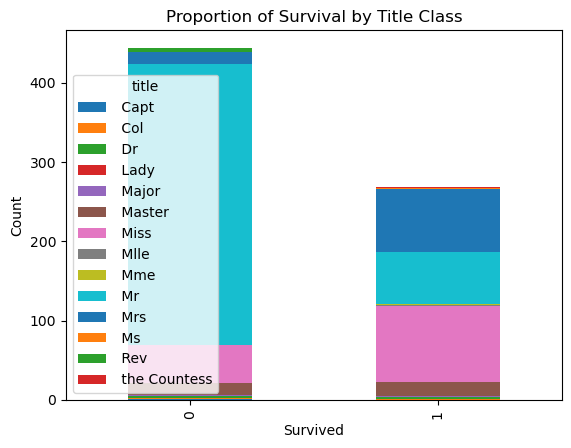

In [173]:
counts = df_duplicates.groupby(['Survived', 'title']).size().unstack()
counts.plot(kind='bar', stacked=True)
plt.title('Proportion of Survival by Title Class')
plt.ylabel('Count')
plt.show()

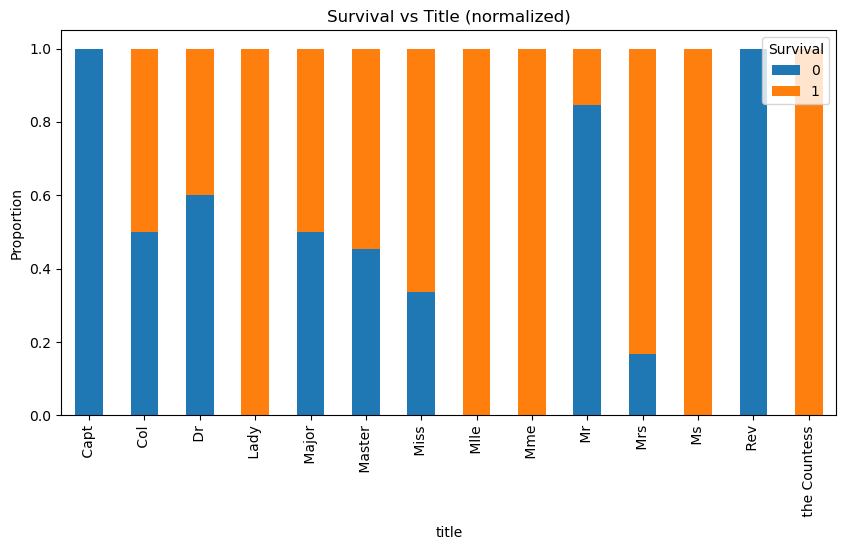

In [174]:
ct = pd.crosstab(df_duplicates['title'], df_duplicates['Survived'], normalize='index')

ct.plot(kind='bar', stacked=True, figsize=(10,5))
plt.ylabel('Proportion')
plt.title('Survival vs Title (normalized)')
plt.legend(title='Survival')
plt.show()


Some of these are problematic since there were only one Countess and one lady so no conclusion can be made to unique values

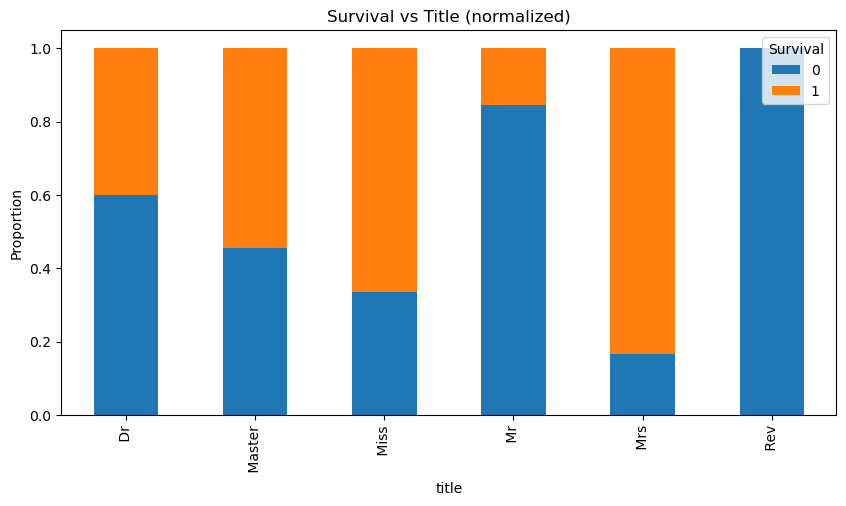

In [175]:
mask_not_unique = df_duplicates['title'].map(
    df_duplicates['title'].value_counts()
) > 4
ct = pd.crosstab(
    df_duplicates.loc[mask_not_unique, 'title'],
    df_duplicates.loc[mask_not_unique, 'Survived'],
    normalize='index'
)
ct.plot(kind='bar', stacked=True, figsize=(10,5))
plt.ylabel('Proportion')
plt.title('Survival vs Title (normalized)')
plt.legend(title='Survival')
plt.show()


Well, yes there are some cases where you have more chances of survival according to your title but mostly it is related to sex "Mrs" and  "Miss" survive more. And men die more. Since, we have the sex column the name column is useless for models that don't want high correlation between features. Of course for some other models this could be helpful.

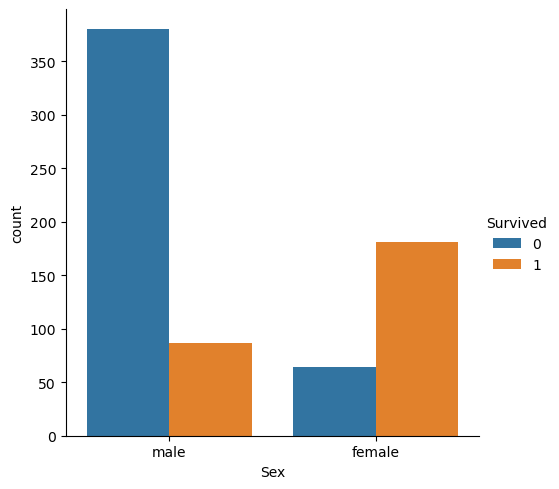

In [176]:
sns.catplot(data=df_duplicates, kind='count', x='Sex', hue='Survived')
plt.show()

# Data Preparation

In [177]:
train = df_train.copy()

## Data Cleaning

In [178]:
print(train.isna().sum())

PassengerId      0
Pclass           0
Name             0
Sex              0
Age            140
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          553
Embarked         2
Survived         0
dtype: int64


In [179]:
print(train.isna().mean() * 100)

PassengerId     0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.662921
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.668539
Embarked        0.280899
Survived        0.000000
dtype: float64


For now, let's try dropping the Cabin Column and try creating a model, if it is unsatisfactory then we try other methods. Or use, A model that accepts missing values.

In [180]:
train = train.drop(columns="Cabin")

In [181]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(strategy='mean')

train['Age'] = age_imputer.fit_transform(train[['Age']])

print(train['Age'].isna().sum())


0


In [182]:
embarked_imputer = SimpleImputer(strategy='most_frequent')

train['Embarked'] = embarked_imputer.fit_transform(train[['Embarked']]).ravel()

print(train['Embarked'].isna().sum())


0


## Feature Selection

In [183]:
print(train.columns)

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Embarked', 'Survived'],
      dtype='object')


In [184]:
train = train.drop(columns=['PassengerId', 'Ticket'])

## Feature Engineering

In [185]:
train['Ncompanions'] = train['Parch'].add(train['SibSp'])

train = train.drop(columns=['Parch', 'SibSp'])

print(train.columns)

Index(['Pclass', 'Name', 'Sex', 'Age', 'Fare', 'Embarked', 'Survived',
       'Ncompanions'],
      dtype='object')


In [186]:
from sklearn.preprocessing import FunctionTransformer

def extract_title_df(X):
    X = pd.DataFrame(X, columns=['Name'])
    titles = X['Name'].apply(
        lambda name: re.search(r",\s*([^\.]+)\.", name).group(1)
        if pd.notnull(name) else None
    )
    return titles.to_frame(name='Title')


In [187]:
name_imputer = FunctionTransformer(extract_title_df)

train[['Title']] = name_imputer.fit_transform(train[['Name']])

print(train['Title'].value_counts(), train.columns)

Title
Mr              419
Miss            143
Mrs              96
Master           33
Rev               5
Dr                5
Major             2
Col               2
Mlle              2
Capt              1
Mme               1
Ms                1
the Countess      1
Lady              1
Name: count, dtype: int64 Index(['Pclass', 'Name', 'Sex', 'Age', 'Fare', 'Embarked', 'Survived',
       'Ncompanions', 'Title'],
      dtype='object')


In [188]:
train = train.drop(columns=['Name'])

In [189]:
print(train.columns)

Index(['Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'Survived', 'Ncompanions',
       'Title'],
      dtype='object')


In [190]:
from sklearn.preprocessing import OneHotEncoder

on_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded = on_encoder.fit_transform(train[['Embarked']])

encoded_df = pd.DataFrame(
    encoded,
    columns=on_encoder.get_feature_names_out(['Embarked']),
    index=train.index
)

train = pd.concat([train.drop(columns=['Embarked']), encoded_df], axis=1)

print(train.columns)

Index(['Pclass', 'Sex', 'Age', 'Fare', 'Survived', 'Ncompanions', 'Title',
       'Embarked_C', 'Embarked_Q', 'Embarked_S'],
      dtype='object')


In [191]:
from sklearn.preprocessing import OrdinalEncoder

od_encoder = OrdinalEncoder()

train['Sex'] = od_encoder.fit_transform(train[['Sex']]).astype('int')

print(train.columns, train.Sex.value_counts())

Index(['Pclass', 'Sex', 'Age', 'Fare', 'Survived', 'Ncompanions', 'Title',
       'Embarked_C', 'Embarked_Q', 'Embarked_S'],
      dtype='object') Sex
1    467
0    245
Name: count, dtype: int64


## Feature Scaling

In [192]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler()

minmax_cols = ['Ncompanions', 'Fare']

train[minmax_cols] = min_max_scaler.fit_transform(train[minmax_cols])

print(train.describe())

           Pclass         Sex         Age        Fare    Survived  \
count  712.000000  712.000000  712.000000  712.000000  712.000000   
mean     2.330056    0.655899   29.498846    0.063604    0.376404   
std      0.824584    0.475408   12.994304    0.101438    0.484824   
min      1.000000    0.000000    0.420000    0.000000    0.000000   
25%      2.000000    0.000000   22.000000    0.015469    0.000000   
50%      3.000000    1.000000   29.498846    0.028213    0.000000   
75%      3.000000    1.000000   35.000000    0.059532    1.000000   
max      3.000000    1.000000   80.000000    1.000000    1.000000   

       Ncompanions  Embarked_C  Embarked_Q  Embarked_S  
count   712.000000  712.000000  712.000000  712.000000  
mean      0.093258    0.175562    0.084270    0.740169  
std       0.168253    0.380714    0.277987    0.438850  
min       0.000000    0.000000    0.000000    0.000000  
25%       0.000000    0.000000    0.000000    0.000000  
50%       0.000000    0.000000    0.

In [193]:
from sklearn.preprocessing import StandardScaler

st_scaler = StandardScaler()

train['Age'] = st_scaler.fit_transform(train[['Age']])

print(train.describe())

           Pclass         Sex           Age        Fare    Survived  \
count  712.000000  712.000000  7.120000e+02  712.000000  712.000000   
mean     2.330056    0.655899  1.509404e-16    0.063604    0.376404   
std      0.824584    0.475408  1.000703e+00    0.101438    0.484824   
min      1.000000    0.000000 -2.239388e+00    0.000000    0.000000   
25%      2.000000    0.000000 -5.774929e-01    0.015469    0.000000   
50%      3.000000    1.000000  2.735977e-16    0.028213    0.000000   
75%      3.000000    1.000000  4.236488e-01    0.059532    1.000000   
max      3.000000    1.000000  3.889139e+00    1.000000    1.000000   

       Ncompanions  Embarked_C  Embarked_Q  Embarked_S  
count   712.000000  712.000000  712.000000  712.000000  
mean      0.093258    0.175562    0.084270    0.740169  
std       0.168253    0.380714    0.277987    0.438850  
min       0.000000    0.000000    0.000000    0.000000  
25%       0.000000    0.000000    0.000000    0.000000  
50%       0.000000

Putting a scaled pclass for logistic regression and SVM

In [194]:
pclass_scaler = MinMaxScaler()

train['scaled_pclass'] = pclass_scaler.fit_transform(train[['Pclass']]).ravel()

print(train.describe())

           Pclass         Sex           Age        Fare    Survived  \
count  712.000000  712.000000  7.120000e+02  712.000000  712.000000   
mean     2.330056    0.655899  1.509404e-16    0.063604    0.376404   
std      0.824584    0.475408  1.000703e+00    0.101438    0.484824   
min      1.000000    0.000000 -2.239388e+00    0.000000    0.000000   
25%      2.000000    0.000000 -5.774929e-01    0.015469    0.000000   
50%      3.000000    1.000000  2.735977e-16    0.028213    0.000000   
75%      3.000000    1.000000  4.236488e-01    0.059532    1.000000   
max      3.000000    1.000000  3.889139e+00    1.000000    1.000000   

       Ncompanions  Embarked_C  Embarked_Q  Embarked_S  scaled_pclass  
count   712.000000  712.000000  712.000000  712.000000     712.000000  
mean      0.093258    0.175562    0.084270    0.740169       0.665028  
std       0.168253    0.380714    0.277987    0.438850       0.412292  
min       0.000000    0.000000    0.000000    0.000000       0.000000  


## Data Preparation Pipeline

In [195]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

### Custom Transformers

In [196]:
from sklearn.base import BaseEstimator,TransformerMixin
from sklearn.preprocessing import FunctionTransformer

In [197]:
class ColumnAdder(BaseEstimator, TransformerMixin):
    def __init__(self, cols=[], column_name='', drop=True):
        self.cols = cols
        self.column_name = column_name
        self.drop = drop
        self._output_config = None

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        X = pd.DataFrame(X).copy()
        X[self.column_name] = X[self.cols[0]]
        
        for i in range(1, len(self.cols)):
            X[self.column_name] = X[self.column_name].add(X[self.cols[i]])
        
        if self.drop == True:
            X = X.drop(columns=self.cols)

        if self._output_config == "pandas":
            return X
        
        return X.to_numpy()

    def set_output(self, *, transform=None):
        """Enable set_output API compatibility."""
        self._output_config = transform
        return self

In [198]:
class TitleCreator(BaseEstimator, TransformerMixin):
    def __init__(self, col='Name'):
        self.col = col
        self._output_config = None

    def fit(self, X, y=None):
        return self

    def extract_title_df(self, X):
        titles = X[self.col].apply(
            lambda name: re.search(r",\s*([^\.]+)\.", name).group(1)
            if pd.notnull(name) else None
        )
        return titles.to_frame(name='Title')

    def transform(self, X, y=None):
        X = pd.DataFrame(X).copy()
        title_df = self.extract_title_df(X)
        X = X.join(title_df)
        
        if self._output_config == "pandas":
            return X
        
        return X.to_numpy()
    

    def set_output(self, *, transform=None):
        """Enable set_output API compatibility."""
        self._output_config = transform
        return self

In [199]:
class ColumnDropper(BaseEstimator, TransformerMixin):
    def __init__(self, cols=[]):
        self.cols = cols
        self._output_config = None

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        X = pd.DataFrame(X).copy()
        X = X.drop(columns=self.cols)
        
        if self._output_config == "pandas":
            return X
        
        return X.to_numpy()

    def set_output(self, *, transform=None):
        """Enable set_output API compatibility."""
        self._output_config = transform
        return self

### Pipeline

In [200]:
embarked_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoded', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))

])

age_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

col_trans = ColumnTransformer(
    transformers = [
        ('Age', age_pipeline, ['Age']),
        ('Embarked', embarked_pipeline, ['Embarked']),
        ('enc_Sex', OrdinalEncoder(), ['Sex']),
        ('minmax', MinMaxScaler(), ['Pclass', 'Ncompanions', 'Fare'])
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

col_trans.set_output(transform='pandas')

preprocess_pipeline = Pipeline([
    ('Ncompanions', ColumnAdder(cols=['Parch', 'SibSp'], column_name='Ncompanions')),
    ('Title', TitleCreator()),
    ('transformed', col_trans),
    ('dropper', ColumnDropper(cols=['PassengerId', 'Name', 'Ticket', 'Cabin', 'Title']))
])

preprocess_pipeline.set_output(transform='pandas')

Pipeline(steps=[('Ncompanions',
                 ColumnAdder(cols=['Parch', 'SibSp'],
                             column_name='Ncompanions')),
                ('Title', TitleCreator()),
                ('transformed',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('Age',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age']),
                                                 ('Embarked',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoded',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Embarked']),
                                                 ('enc_Sex', OrdinalEncoder(),
                                                  ['Sex']),
                                                 ('minmax', MinMaxScaler(),
                                                  ['Pclass', 'Ncompanions',
                                                   'Fare'])],
                                   verbose_feature_names_out=False)),
                ('dropper',
                 ColumnDropper(cols=['PassengerId', 'Name', 'Ticket', 'Cabin',
                                     'Title']))])

In [201]:
train = df_train.copy()

train = preprocess_pipeline.fit_transform(train)

# Model Selection

In [202]:
X_train = train.drop(columns=['Survived'])
y_train = train['Survived']

In [203]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression,SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV, StratifiedKFold

In [204]:
def shortlistModels(models, X, y, cv, scoring, n_jobs):
    scores = {}
    for model in models:
        score = cross_val_score(models[model], X, y, cv=cv, scoring=scoring, n_jobs=n_jobs)
        scores[model] = [score.mean(), score.std()]
        
    return scores

In [205]:
models = {
    'sgd': SGDClassifier(random_state=42),
    'knn': KNeighborsClassifier(),
    'lg': LogisticRegression(random_state=42),
    'dt': DecisionTreeClassifier(random_state=42),
    'rf': RandomForestClassifier(random_state=42),
    'gb': GradientBoostingClassifier(random_state=42),
    'ab': AdaBoostClassifier(random_state=42),
    'xgb': XGBClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scores = shortlistModels(models, X_train, y_train, cv, 'roc_auc', -1)

for model in scores:
    print(f'{model} has a mean score of: {scores[model][0]:.4f} and a standard deviation of: {scores[model][1]:.4f}')

sgd has a mean score of: 0.8264 and a standard deviation of: 0.0406
knn has a mean score of: 0.8412 and a standard deviation of: 0.0462
lg has a mean score of: 0.8479 and a standard deviation of: 0.0368
dt has a mean score of: 0.7551 and a standard deviation of: 0.0673
rf has a mean score of: 0.8476 and a standard deviation of: 0.0462
gb has a mean score of: 0.8637 and a standard deviation of: 0.0359
ab has a mean score of: 0.8370 and a standard deviation of: 0.0426
xgb has a mean score of: 0.8479 and a standard deviation of: 0.0473


## Random Search on best models

In [206]:
def multiRandomizedSearchCV(models, X, y, param_dist, n_iter, cv, scoring, n_jobs, random_state):
    results = {}
    for model in models:
        rs = RandomizedSearchCV(estimator = models[model], param_distributions=param_dist[model], n_iter=n_iter, cv=cv, n_jobs=n_jobs, random_state=random_state)
        rs.fit(X, y)
        print("For:", model)
        print("Best Parameters:", rs.best_params_)
        print("Best CV Accuracy:", rs.best_score_)
        results[model] = rs

    return results

In [207]:
from random import randint, uniform


In [208]:
best_models = {
    'gb': GradientBoostingClassifier(random_state=42),
    'xgb': XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False, random_state=42),
    'knn': KNeighborsClassifier(),
    'rf': RandomForestClassifier(
            n_jobs=-1,
            random_state=42,
            oob_score=False,
            bootstrap=True
        )
}

param_dist = {
    'gb': {
        'n_estimators': range(50, 301, 20),
        'learning_rate': np.linspace(0.01, 1, 15),
        'max_depth': range(5, 10),
        'min_samples_leaf': np.linspace(0.01, 0.95, 15),
        'subsample': [0.8, 1.0],
        'max_features': ['sqrt', 'log2', None]
    },
    'knn': {
        'n_neighbors': list(range(1, 21)),
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan', 'minkowski']
    },
    'xgb': {
        'n_estimators': range(50, 500, 20),          # number of boosting rounds
        'max_depth': range(2, 10),               # tree depth
        'learning_rate': np.linspace(0.01, 0.3, 20),       # step size shrinkage
        'subsample': [0.8, 1],            # row sampling
        'colsample_bytree': np.linspace(0, 0.9, 15),     # feature sampling
        'gamma': np.linspace(0, 5, 30),                    # min loss reduction
        'reg_alpha': np.linspace(0, 1, 15),                # L1 regularization
        'reg_lambda': np.linspace(0, 1, 15)               # L2 regularization
    },
    'rf': {
        'n_estimators': [200, 300, 500],   # stability > brute force
        'max_depth': [None, 5, 8, 12, 16], # MOST important parameter
        'min_samples_split': [2, 5, 10, 20],
        'min_samples_leaf': [1, 2, 5, 10],
        'max_features': ['sqrt', 'log2', 0.3, 0.5, 0.7],
    }
    
}

results = multiRandomizedSearchCV(best_models, X_train, y_train, param_dist, 50, cv, 'roc_auc', -1, 42)




For: gb
Best Parameters: {'subsample': 1.0, 'n_estimators': 110, 'min_samples_leaf': 0.07714285714285714, 'max_features': None, 'max_depth': 8, 'learning_rate': 0.15142857142857144}
Best CV Accuracy: 0.828755868544601


c:\Users\bahad\miniconda3\Lib\site-packages\xgboost\training.py:199: UserWarning: [17:14:26] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


For: xgb
Best Parameters: {'subsample': 1, 'reg_lambda': 0.8571428571428571, 'reg_alpha': 1.0, 'n_estimators': 410, 'max_depth': 7, 'learning_rate': 0.16263157894736843, 'gamma': 1.7241379310344829, 'colsample_bytree': 0.7714285714285716}
Best CV Accuracy: 0.8413928012519563
For: knn
Best Parameters: {'weights': 'uniform', 'n_neighbors': 12, 'metric': 'euclidean'}
Best CV Accuracy: 0.8231416275430361
For: rf
Best Parameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 5}
Best CV Accuracy: 0.832942097026604


In [209]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning
)

In [210]:
def getTopNIter(results, result, n):
    result_df = pd.DataFrame(results[result].cv_results_).copy()
    top_n = result_df.sort_values(by='mean_test_score', ascending=False)
    return top_n.head(n)

In [211]:
top_20_models = {}
for model in results:
    top_20_models[model] = getTopNIter(results, model, 20)

## Logistic Regression Tuning

In [212]:
lr = LogisticRegression(random_state=42)
lr_models = {'lr1': lr, 'lr2': lr}
param_dist_lr = {
    'lr1': {
        'solver': ['lbfgs', 'sag'],
        'penalty': ['l2'],
        'C': np.logspace(-4, 2, 20)
    },
    'lr2': {
        'solver': ['liblinear'],
        'penalty': ['l1', 'l2'],
        'C': np.logspace(-4, 2, 20)
    },
}

lr_results = {}
for model in lr_models:
    gs = (GridSearchCV(estimator=lr, param_grid=param_dist_lr[model], cv=cv, scoring='roc_auc', error_score=np.nan))
    lr_results[model] = gs.fit(X_train, y_train)
    print(f'{model} gave us:')
    print('best score:', lr_results[model].best_score_)
    print('best params:', lr_results[model].best_params_)
    

lr1 gave us:
best score: 0.848470315692538
best params: {'C': 0.615848211066026, 'penalty': 'l2', 'solver': 'lbfgs'}
lr2 gave us:
best score: 0.8484613945725055
best params: {'C': 0.615848211066026, 'penalty': 'l2', 'solver': 'liblinear'}


## KNN Tuning

In [213]:
def prepare_param_score_df(top_n_df):
    param_cols = [c for c in top_n_df.columns if c.startswith("param_")]
    
    plot_df = top_n_df[param_cols + ["mean_test_score"]].copy()
    
    # Convert categorical params to string (important!)
    for col in param_cols:
        plot_df[col] = plot_df[col].astype(str)
    
    return plot_df


In [214]:
def split_param_types(df):
    numeric_params = []
    categorical_params = []
    
    for col in df.columns:
        if col == "mean_test_score":
            continue
        
        try:
            df[col].astype(float)
            numeric_params.append(col)
        except ValueError:
            categorical_params.append(col)
    
    return numeric_params, categorical_params


In [215]:
def plot_numeric_params(df, numeric_params):
    for param in numeric_params:
        plt.figure()
        plt.scatter(df[param].astype(float), df["mean_test_score"])
        plt.xlabel(param)
        plt.ylabel("Mean CV Score")
        plt.title(f"{param} vs Mean CV Score")
        plt.show()


In [216]:
def plot_categorical_params(df, categorical_params):
    for param in categorical_params:
        plt.figure()
        df.boxplot(column="mean_test_score", by=param)
        plt.xlabel(param)
        plt.ylabel("Mean CV Score")
        plt.title(f"{param} vs Mean CV Score")
        plt.suptitle("")
        plt.show()


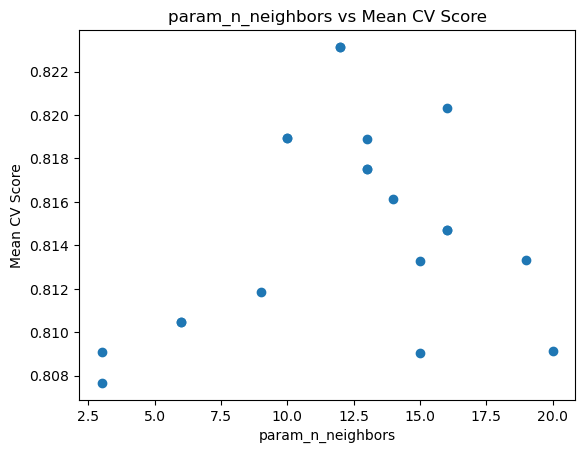

In [217]:
plot_df = prepare_param_score_df(top_20_models['knn'])
num_params, cat_params = split_param_types(plot_df)
plot_numeric_params(plot_df, num_params)

<Figure size 640x480 with 0 Axes>

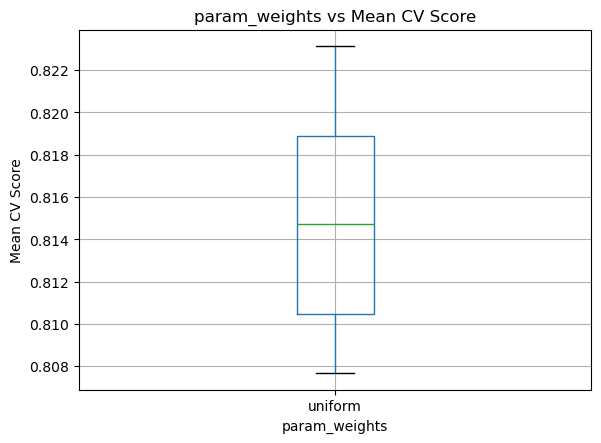

<Figure size 640x480 with 0 Axes>

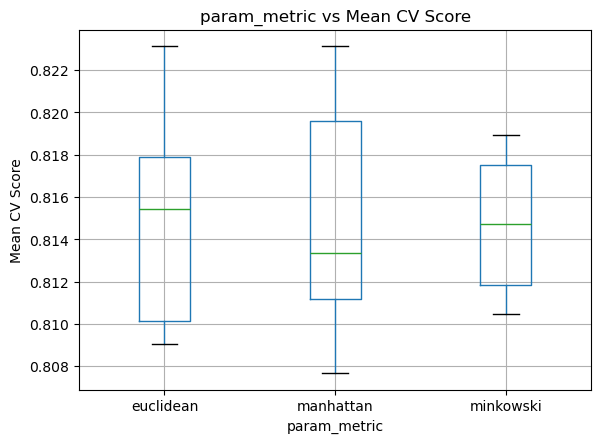

In [218]:
plot_categorical_params(plot_df, cat_params)


<Figure size 640x480 with 0 Axes>

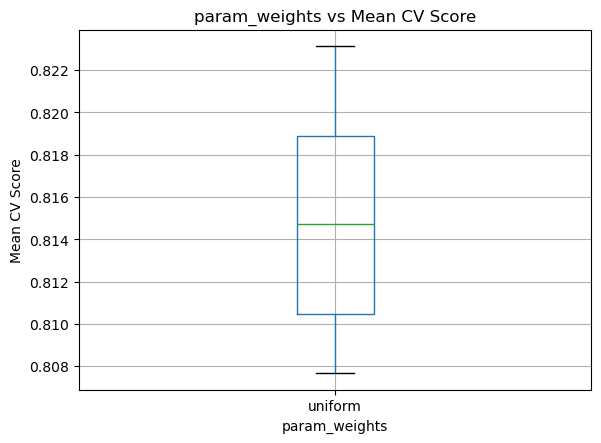

<Figure size 640x480 with 0 Axes>

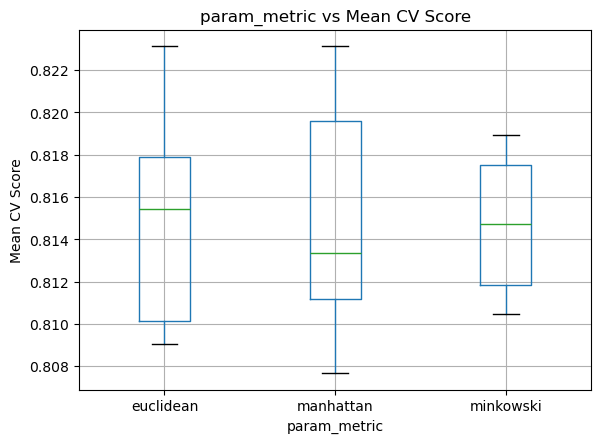

In [219]:
plot_categorical_params(plot_df, cat_params)

In [220]:
param_grid = {
    "n_neighbors": list(range(10, 16)),
    "weights": ["uniform"],
    "metric": ["minkowski"],
}

grid_search_knn = GridSearchCV(
    estimator=best_models['knn'],
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search_knn.fit(X_train, y_train)

print(grid_search_knn.best_params_)
print(grid_search_knn.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
{'metric': 'minkowski', 'n_neighbors': 13, 'weights': 'uniform'}
0.8484728030784847


## Gradient Boosting Tuning

In [221]:
import pandas as pd
import re

def selectColumnsByRegex(df, regex_pattern, extra_cols):

    regex_cols = [col for col in df.columns if re.search(regex_pattern, col)]
    selected_cols = list(set(regex_cols + extra_cols))

    return df[selected_cols]


In [222]:
top_20_gb = top_20_models['gb']
top_20_gb = selectColumnsByRegex(top_20_gb, r"param_[A-Za-z]+", ["mean_test_score"]).sort_values(by="mean_test_score", ascending=False)

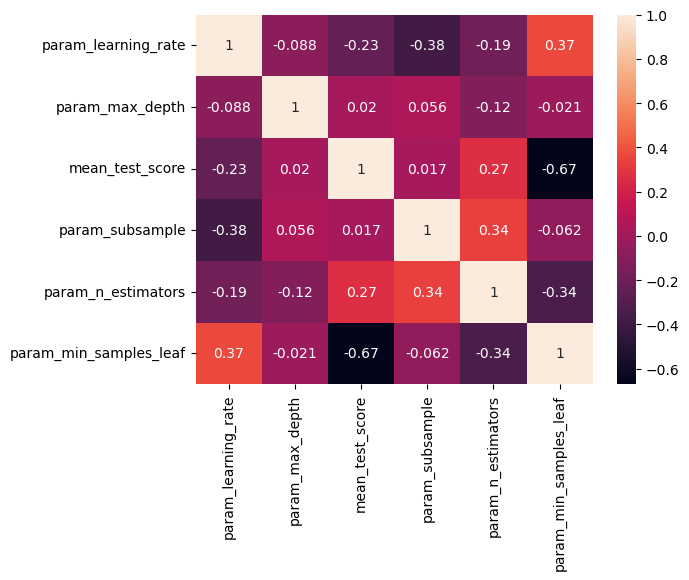

In [223]:
corr_gb = top_20_gb.drop(columns=['param_max_features']).corr()

sns.heatmap(corr_gb, annot=True)
plt.show()

In [224]:
param_grid = {
    'learning_rate': [0.01, 0.03, 0.05, 0.07],
    'n_estimators': [300, 400, 500],
    'min_samples_leaf': [1, 2, 5],
    'max_depth': [3, 4],
    'subsample': [0.8, 0.9, 1.0]
}

grid_search_gb = GridSearchCV(
    estimator=best_models['gb'],
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search_gb.fit(X_train, y_train)

print(grid_search_gb.best_params_)
print(grid_search_gb.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


c:\Users\bahad\miniconda3\Lib\site-packages\numpy\ma\core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


{'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 300, 'subsample': 1.0}
0.8646917464518694


## XBG Tuning

In [225]:
param_grid = {
    "n_estimators": [350, 450, 500],
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_depth": [6, 7, 8],
    "gamma": [2.0, 3.0],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.6, 0.8],
    'reg_alpha':[0.5],
    'reg_lambda':[0.5]
}

grid_search_xgb = GridSearchCV(
    estimator=best_models['xgb'],
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search_xgb.fit(X_train, y_train)

print(grid_search_xgb.best_params_)
print(grid_search_xgb.best_score_)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits
{'colsample_bytree': 0.6, 'gamma': 2.0, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 450, 'reg_alpha': 0.5, 'reg_lambda': 0.5, 'subsample': 0.8}
0.8665840307177491


c:\Users\bahad\miniconda3\Lib\site-packages\xgboost\training.py:199: UserWarning: [17:16:28] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [227]:
param_grid = {
    "reg_alpha": [0.1, 0.3, 0.7],
    "reg_lambda": [0.1, 0.3, 0.7],
}

grid_search_xgb2 = GridSearchCV(
    estimator=grid_search_xgb.best_estimator_,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search_xgb2.fit(X_train, y_train)

print(grid_search_xgb2.best_params_)
print(grid_search_xgb2.best_score_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
{'reg_alpha': 0.1, 'reg_lambda': 0.7}
0.8684834306959068


c:\Users\bahad\miniconda3\Lib\site-packages\xgboost\training.py:199: UserWarning: [17:17:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## Random Forest Tuning

In [228]:
top_20_rf = top_20_models['rf']
top_20_rf = selectColumnsByRegex(top_20_rf, r"param_[A-Za-z]+", ["mean_test_score"]).sort_values(by="mean_test_score", ascending=False)

In [229]:
param_grid_rf = {
    "n_estimators": [300, 400, 500],
    "max_depth": [5, 8, None],
    "min_samples_split": [5, 10, 20],
    "min_samples_leaf": [1, 2],
    "max_features": [0.3, 0.5, 0.7, "sqrt", "log2"],
}

grid_search_rf = GridSearchCV(
    estimator=best_models['rf'],
    param_grid=param_grid_rf,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

print(grid_search_rf.best_params_)
print(grid_search_rf.best_score_)

Fitting 5 folds for each of 270 candidates, totalling 1350 fits
{'max_depth': 8, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}
0.863068971461488


## Final Model

In [230]:
results_final = {
    'rf': grid_search_rf,
    'xgb': grid_search_xgb,
    'xgb2': grid_search_xgb2,
    'gb': grid_search_gb,
    'knn': grid_search_knn,
    'lr1': lr_results['lr1'],
    'lr2': lr_results['lr2']
}

for model in results_final:
    if model == 'lr1' or model == 'lr2':
        print(f'Default lg has a mean score of: {scores["lg"][0]:.4f}')
    else:
        if model == 'xgb2':
            print(f'Default XGB has a mean score of: {scores['xgb'][0]:.4f}')
        else:
            print(f'Default {model} has a mean score of: {scores[model][0]:.4f}')
    print(f'Best Tuned {model} has a mean score of: {results_final[model].best_score_:.4f}')
    

Default rf has a mean score of: 0.8476
Best Tuned rf has a mean score of: 0.8631
Default xgb has a mean score of: 0.8479
Best Tuned xgb has a mean score of: 0.8666
Default XGB has a mean score of: 0.8479
Best Tuned xgb2 has a mean score of: 0.8685
Default gb has a mean score of: 0.8637
Best Tuned gb has a mean score of: 0.8647
Default knn has a mean score of: 0.8412
Best Tuned knn has a mean score of: 0.8485
Default lg has a mean score of: 0.8479
Best Tuned lr1 has a mean score of: 0.8485
Default lg has a mean score of: 0.8479
Best Tuned lr2 has a mean score of: 0.8485


In [231]:
model = grid_search_xgb2.best_estimator_

## Prediction Pipeline

In [232]:
X_train = df_train.drop(columns=['Survived']).copy()
y_train = df_train['Survived'].copy()

pipeline = Pipeline([
    ('preprocess', preprocess_pipeline),
    ('model', model)
])

pipeline.fit(X_train, y_train)


c:\Users\bahad\miniconda3\Lib\site-packages\xgboost\training.py:199: UserWarning: [17:22:14] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\bahad\miniconda3\Lib\site-packages\sklearn\compose\_column_transformer.py:1623: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocess',
                 Pipeline(steps=[('Ncompanions',
                                  ColumnAdder(cols=['Parch', 'SibSp'],
                                              column_name='Ncompanions')),
                                 ('Title', TitleCreator()),
                                 ('transformed',
                                  ColumnTransformer(remainder='passthrough',
                                                    transformers=[('Age',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer()),
                                                                                   ('scaler',
                                                                                    StandardScaler())]),
                                                                   ['Age']),
                                                                  ('Embarked',
                                                                   Pipeline(steps=[('imputer',
                                                                                    S...
                               feature_types=None, feature_weights=None,
                               gamma=2.0, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=450, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [233]:
print(pipeline.score(X_train, y_train))

0.8637640449438202


In [234]:
y_pred = pipeline.predict(X_test)

In [235]:
from sklearn.metrics import roc_auc_score, classification_report

In [236]:
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       105
           1       0.82      0.72      0.76        74

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.81       179

